In [1]:

!nvidia-smi

import torch

print("PyTorch Version:", torch.__version__)
print("CUDA Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU Name:", torch.cuda.get_device_name(0))
else:
    print("GPU not available. Select GPU runtime.")


Mon Nov 23 08:16:07 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   43C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:

!pip install -q torch torchvision onnx onnxscript onnxruntime


In [3]:

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms

import onnx
import onnxruntime as ort

import numpy as np
import os

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("All Libraries Imported Successfully!")
print("Execution Device:", device)


All Libraries Imported Successfully!
Execution Device: cuda


In [4]:

class CNNModel(nn.Module):

    def __init__(self):
        super(CNNModel, self).__init__()

        self.conv1 = nn.Conv2d(1, 16, 3)
        self.relu = nn.ReLU()
        self.pool = nn.MaxPool2d(2)

        self.fc1 = nn.Linear(16 * 13 * 13, 128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = self.pool(self.relu(self.conv1(x)))
        x = x.view(x.size(0), -1)
        x = self.relu(self.fc1(x))
        x = self.fc2(x)

        return x


model = CNNModel().to(device)

print(model)
print("Model Architecture Created Successfully!")


CNNModel(
  (conv1): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1))
  (relu): ReLU()
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=2704, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)
Model Architecture Created Successfully!


In [5]:

transform = transforms.ToTensor()

train_dataset = torchvision.datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = torchvision.datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

train_loader = torch.utils.data.DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
)

test_loader = torch.utils.data.DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False
)

print("Dataset Loaded Successfully!")
print("Training Images:", len(train_dataset))
print("Testing Images:", len(test_dataset))


100%|██████████| 9.91M/9.91M [00:00<00:00, 18.5MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 492kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.61MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 14.8MB/s]

Dataset Loaded Successfully!
Training Images: 60000
Testing Images: 10000


In [6]:

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

epochs = 2

for epoch in range(epochs):

    model.train()
    running_loss = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    print(
        f"Epoch {epoch+1}/{epochs}, "
        f"Loss: {running_loss/len(train_loader):.4f}"
    )

print("Model Training Completed Successfully!")


Epoch 1/2, Loss: 0.2842
Epoch 2/2, Loss: 0.0913
Model Training Completed Successfully!


In [7]:

os.makedirs("artifacts", exist_ok=True)

checkpoint_path = "artifacts/model_checkpoint.pth"

torch.save({
    "model_state_dict": model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    "epochs": epochs
}, checkpoint_path)

print("Checkpoint Saved Successfully!")
print("Location:", checkpoint_path)


Checkpoint Saved Successfully!
Location: artifacts/model_checkpoint.pth


In [8]:

loaded_model = CNNModel().to(device)

checkpoint = torch.load(
    "artifacts/model_checkpoint.pth",
    map_location=device,
    weights_only=True
)

loaded_model.load_state_dict(
    checkpoint["model_state_dict"]
)

loaded_model.eval()

print("Checkpoint Loaded Successfully!")
print("Model Ready for Inference!")


Checkpoint Loaded Successfully!
Model Ready for Inference!


In [9]:

import onnx
import onnxscript

dummy_input = torch.randn(
    1, 1, 28, 28
).to(device)

onnx_path = "artifacts/model.onnx"

torch.onnx.export(
    loaded_model,
    dummy_input,
    onnx_path,
    input_names=["input"],
    output_names=["output"],
    opset_version=17,
    dynamo=False
)

print("ONNX Conversion Completed Successfully!")
print("ONNX File:", onnx_path)


ONNX Conversion Completed Successfully!
ONNX File: artifacts/model.onnx


/tmp/ipykernel_410/2362050936.py:10: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(


In [10]:

onnx_model = onnx.load(
    "artifacts/model.onnx"
)

onnx.checker.check_model(onnx_model)

print("ONNX Model Validation Successful!")

print("Model Inputs:")
for item in onnx_model.graph.input:
    print(item.name)

print("Model Outputs:")
for item in onnx_model.graph.output:
    print(item.name)


ONNX Model Validation Successful!
Model Inputs:
input
Model Outputs:
output


In [11]:

session = ort.InferenceSession(
    "artifacts/model.onnx",
    providers=["CPUExecutionProvider"]
)

test_image, actual_label = test_dataset[0]

input_data = test_image.unsqueeze(0).numpy()

result = session.run(
    None,
    {"input": input_data}
)

prediction = np.argmax(result[0])

print("Actual Digit:", actual_label)
print("Predicted Digit:", prediction)
print("ONNX Inference Completed Successfully!")


Actual Digit: 7
Predicted Digit: 7
ONNX Inference Completed Successfully!


In [23]:
!pip install -q cuda-python

In [13]:

import tensorrt as trt

print("TensorRT Version:", trt.__version__)
print("TensorRT Installed Successfully!")


TensorRT Version: 11.5.0.63
TensorRT Installed Successfully!


In [17]:

import tensorrt as trt

# Create logger
logger = trt.Logger(trt.Logger.WARNING)

# Create builder
builder = trt.Builder(logger)

# Create network
network = builder.create_network(0)

# Create ONNX parser
parser = trt.OnnxParser(network, logger)

# Create configuration
config = builder.create_builder_config()

# Set workspace memory
config.set_memory_pool_limit(
    trt.MemoryPoolType.WORKSPACE,
    1 << 30
)

# Load ONNX model
with open("artifacts/model.onnx", "rb") as f:
    onnx_data = f.read()

# Parse ONNX
success = parser.parse(onnx_data)

if not success:
    for i in range(parser.num_errors):
        print(parser.get_error(i))
    raise RuntimeError("ONNX Parsing Failed!")

print("ONNX Parsing Successful!")

# Build TensorRT engine using FP32
serialized_engine = builder.build_serialized_network(
    network,
    config
)

if serialized_engine is None:
    raise RuntimeError("TensorRT Engine Build Failed!")

# Save engine
engine_path = "artifacts/model.engine"

with open(engine_path, "wb") as f:
    f.write(serialized_engine)

print("TensorRT Engine Created Successfully!")
print("Saved at:", engine_path)


ONNX Parsing Successful!
TensorRT Engine Created Successfully!
Saved at: artifacts/model.engine


In [15]:
import tensorrt as trt

print("TensorRT Version:", trt.__version__)


TensorRT Version: 11.5.0.63


In [18]:

import os

print("MODEL ARTEFACTS")
print("-------------------------")

for file in os.listdir("artifacts"):
    path = os.path.join("artifacts", file)

    print(
        file,
        "-",
        round(os.path.getsize(path) / 1024, 2),
        "KB"
    )

print("-------------------------")
print("Verification Completed!")


MODEL ARTEFACTS
-------------------------
model.onnx - 1359.28 KB
model.engine - 1393.64 KB
model_checkpoint.pth - 4082.48 KB
-------------------------
Verification Completed!


In [19]:

import os

folder = "artifacts"

print("===== MODEL ARTEFACT LIFECYCLE =====")

for file in os.listdir(folder):
    path = os.path.join(folder, file)

    size = os.path.getsize(path) / 1024

    print(f"{file} : {size:.2f} KB")

print("====================================")
print("All generated files verified!")


===== MODEL ARTEFACT LIFECYCLE =====
model.onnx : 1359.28 KB
model.engine : 1393.64 KB
model_checkpoint.pth : 4082.48 KB
All generated files verified!


In [20]:

import tensorrt as trt

logger = trt.Logger(trt.Logger.WARNING)

runtime = trt.Runtime(logger)

with open("artifacts/model.engine", "rb") as f:
    engine_data = f.read()

engine = runtime.deserialize_cuda_engine(engine_data)

if engine is None:
    raise RuntimeError("Failed to load TensorRT Engine!")

context = engine.create_execution_context()

if context is None:
    raise RuntimeError("Failed to create execution context!")

print("TensorRT Engine Loaded Successfully!")

print("Input and Output Tensors:")

for i in range(engine.num_io_tensors):
    name = engine.get_tensor_name(i)
    print(name, engine.get_tensor_mode(name))


TensorRT Engine Loaded Successfully!
Input and Output Tensors:
input TensorIOMode.INPUT
output TensorIOMode.OUTPUT


In [21]:

!pip install -q cuda-python


In [24]:
import numpy as np
import torch

# Prepare a test image
test_image, actual_label = test_dataset[0]

# Create PyTorch tensors on GPU for inputs and outputs
# This manages GPU allocation and streams reliably
input_tensor = test_image.unsqueeze(0).to(device)
output_tensor = torch.empty((1, 10), dtype=torch.float32, device=device)

# Set input shape
context.set_input_shape("input", input_tensor.shape)

# Bind the tensor addresses directly using their CUDA pointers
context.set_tensor_address("input", input_tensor.data_ptr())
context.set_tensor_address("output", output_tensor.data_ptr())

# Create a CUDA stream using PyTorch
stream = torch.cuda.current_stream(device=device)

# Execute inference on the stream
success = context.execute_async_v3(stream.cuda_stream)
if not success:
    raise RuntimeError("TensorRT Inference Failed!")

# Synchronize stream to ensure execution completes
stream.synchronize()

# Retrieve predicted digit
prediction = int(torch.argmax(output_tensor).item())

print("TensorRT Inference Successful!")
print("Actual Digit:", actual_label)
print("Predicted Digit:", prediction)

TensorRT Inference Successful!
Actual Digit: 7
Predicted Digit: 7


In [29]:
# PyTorch prediction
loaded_model.eval()

with torch.no_grad():
    pytorch_output = loaded_model(
        test_image.unsqueeze(0).to(device)
    )

pytorch_prediction = pytorch_output.argmax(dim=1).item()

# ONNX prediction
onnx_result = session.run(
    None,
    {"input": input_data}
)

onnx_prediction = int(np.argmax(onnx_result[0]))

# TensorRT prediction (using the variable 'prediction' or output_tensor from our updated TRT execution)
tensorrt_prediction = int(torch.argmax(output_tensor).item())

print("===== MODEL PREDICTION COMPARISON =====")

print("Actual Digit:   ", actual_label)
print("PyTorch:        ", pytorch_prediction)
print("ONNX:           ", onnx_prediction)
print("TensorRT:       ", tensorrt_prediction)

print("=======================================")

===== MODEL PREDICTION COMPARISON =====
Actual Digit:    7
PyTorch:         7
ONNX:            7
TensorRT:        7


In [26]:

import time

# PyTorch inference timing
loaded_model.eval()

start = time.perf_counter()

for _ in range(100):
    with torch.no_grad():
        loaded_model(
            test_image.unsqueeze(0).to(device)
        )

if device.type == "cuda":
    torch.cuda.synchronize()

pytorch_time = (time.perf_counter() - start) / 100 * 1000

# ONNX inference timing
start = time.perf_counter()

for _ in range(100):
    session.run(None, {"input": input_data})

onnx_time = (time.perf_counter() - start) / 100 * 1000

print("===== INFERENCE PERFORMANCE =====")
print(f"PyTorch: {pytorch_time:.3f} ms")
print(f"ONNX:    {onnx_time:.3f} ms")
print("=================================")


===== INFERENCE PERFORMANCE =====
PyTorch: 1.006 ms
ONNX:    0.487 ms


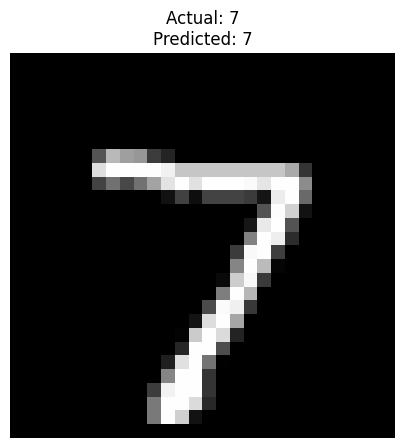

TensorRT Prediction Displayed Successfully!


In [30]:
import matplotlib.pyplot as plt

plt.figure(figsize=(5, 5))

plt.imshow(test_image.squeeze(), cmap="gray")

# Using the local or global prediction variable
plt.title(
    f"Actual: {actual_label}\n"
    f"Predicted: {prediction}"
)

plt.axis("off")
plt.show()

print("TensorRT Prediction Displayed Successfully!")

In [28]:

import shutil
import os

shutil.make_archive(
    "Model_Artefact_Lifecycle",
    "zip",
    "artifacts"
)

print("Final Project ZIP Created!")
print("File: Model_Artefact_Lifecycle.zip")


Final Project ZIP Created!
File: Model_Artefact_Lifecycle.zip


In [31]:

from google.colab import files

files.download("Model_Artefact_Lifecycle.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>